# Практика 10. Итоговый мини-проект и отчёт

**Прикладные технологии ИИ** · 120 минут (2 ч.) · Модуль 5

**Цель:** В составе учебной группы выполнить один небольшой комплексный проект по ИИ и представить отчёт о результатах.

> Это финальная практика курса. За **2 аудиторных часа** вы в мини-команде (2–3 человека) проходите полный цикл ML-проекта (данные → модель → оценка → отчёт) по образцу ниже. Всё делается в классе — никакой домашней доработки.

## Выбор задачи (один на группу)

Рекомендуем **вариант 1** — он гарантированно укладывается в 2 часа. Вариант 2 — для тех, кто хочет посложнее.

| # | Задача | Что используем | Оценка времени |
|---|---|---|---|
| 1 | **Сегментация клиентов магазина**: k-means + профили групп + график | образец ниже, практика 4 | ★ успеваем за 2 ч |
| 2 | **«Какой это цветок?»**: обучение на ирисах + прогноз для нового цветка | практика 3 | ★★ на пределе |
| 3 | **Свой вариант** (согласуйте с преподавателем) | — | зависит от задачи |

## Как делить работу в мини-команде (2–3 человека)

Формальных ролей нет — просто делите этапы:

- **данные + модель** — один участник;
- **оценка + график** — второй;
- **отчёт** — пишете вместе в конце (15–20 минут).

## Тайминг на 2 часа

| Интервал | Этап |
|---|---|
| 0:00–0:10 | Выбор задачи и план |
| 0:10–0:35 | Данные: загрузка, осмотр, очистка |
| 0:35–1:10 | Модель: обучение и метрики |
| 1:10–1:30 | Оценка, график для отчёта |
| 1:30–1:50 | Отчёт по шаблону |
| 1:50–2:00 | Показ преподавателю: 2 минуты на группу |


## Введение

Практика 10 — финальная точка курса. Это **мини-проект на 2 часа**: вы работаете в мини-команде 2–3 человека и проходите полный цикл — от данных до отчёта. Главное отличие от предыдущих практик: нет пошаговой инструкции. Вы сами принимаете решения по образцу ниже и сами отвечаете за результат.

### Чем проектная работа отличается от упражнения

| Упражнение (практики 1–9) | Мини-проект (практика 10) |
|---|---|
| Есть готовый шаблон: «делай раз, делай два» | Есть только цель и образец — как достичь, решаете вы |
| Время: 30–90 минут | Время: 2 аудиторных часа |
| Один автор | Мини-команда 2–3 человека |
| Фокус на технике | Фокус на целом цикле |

### Пять этапов цикла

1. **Данные** — загрузить, осмотреть, почистить (пропуски, дубликаты, выбросы);
2. **Модель** — выбрать алгоритм, обучить, подобрать 1–2 гиперпараметра;
3. **Оценка** — метрики на тесте, один наглядный график;
4. **Отчёт** — 5 коротких разделов по шаблону;
5. **Показ** — 2 минуты преподавателю: задача → метрика → график.

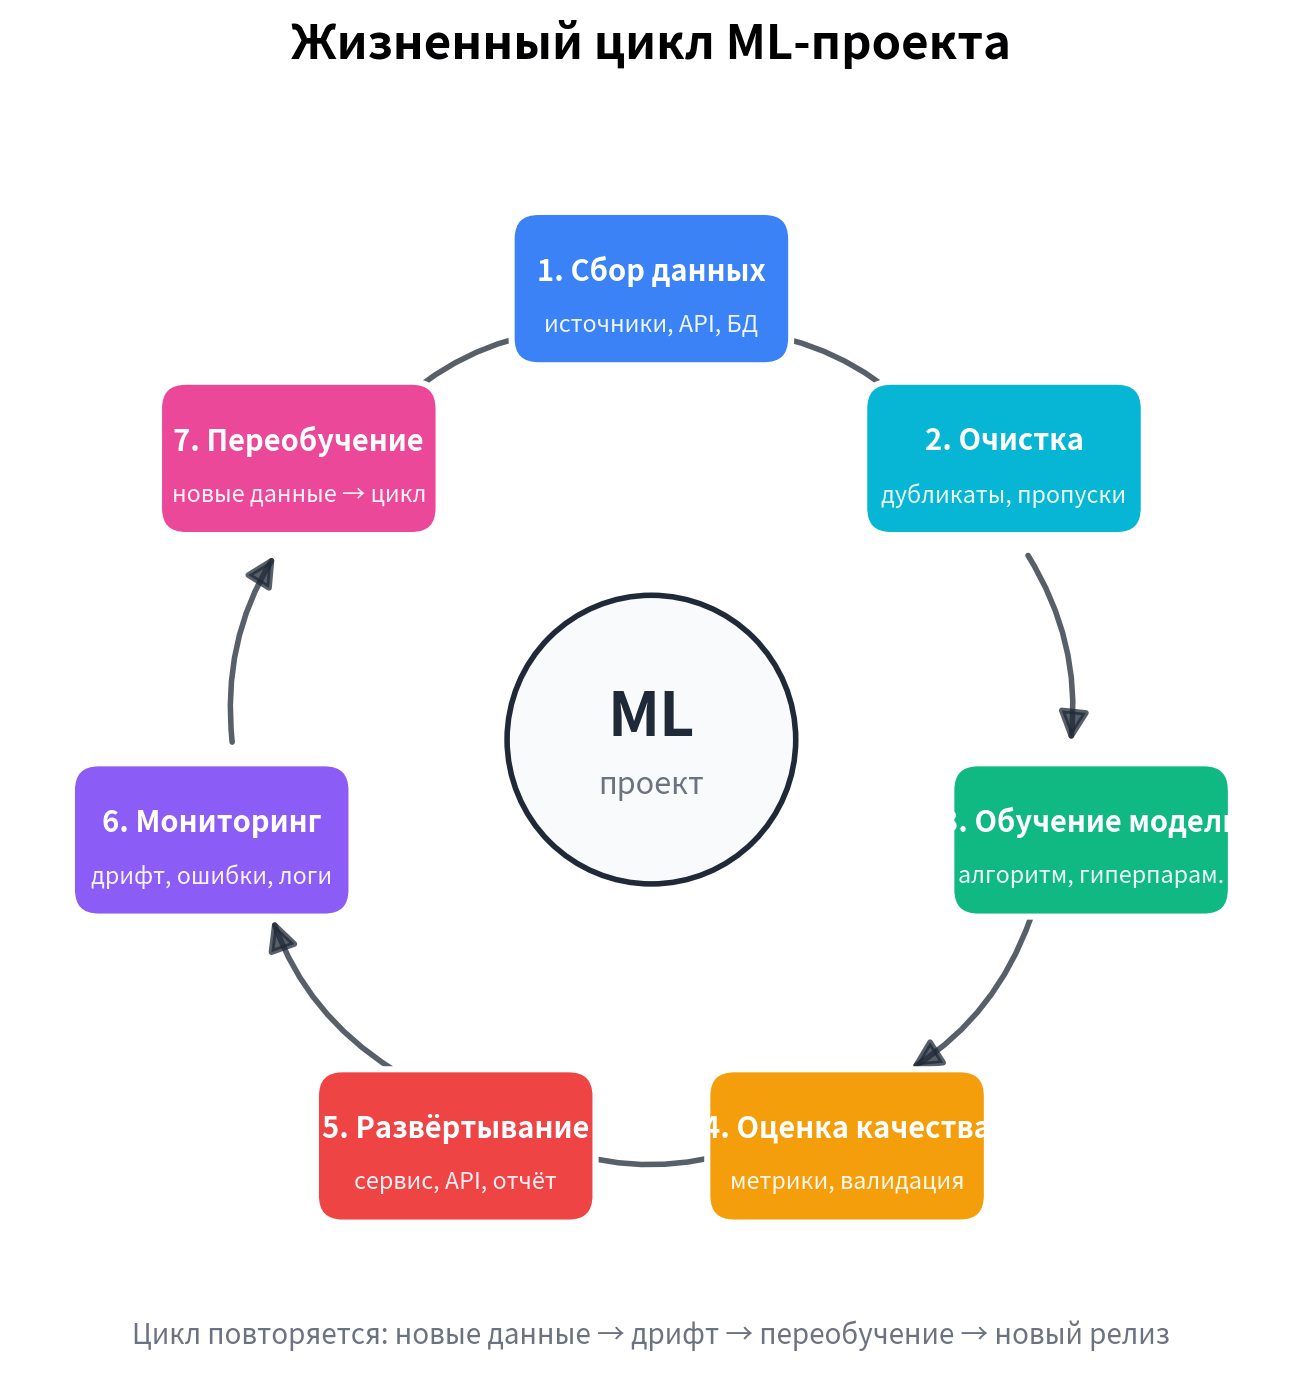

*Жизненный цикл ML-проекта: ваш мини-проект проходит те же этапы в ускоренном темпе — цикл замкнут, после развёртывания начинается мониторинг и переобучение на новых данных.*


In [1]:
# Настройка ноутбука: графики внутри документа, шрифты с кириллицей и иероглифами
%matplotlib inline
import os
# Подавляем предупреждение KMeans о памяти на Windows с MKL
os.environ.setdefault("OMP_NUM_THREADS", "1")

import numpy as np
import pandas as pd
import matplotlib.font_manager as fm
for fp in ['/usr/share/fonts/truetype/chinese/NotoSansSC-Regular.ttf',
           '/usr/share/fonts/truetype/chinese/NotoSansSC-Bold.ttf']:
    if os.path.exists(fp):
        fm.fontManager.addfont(fp)
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Noto Sans SC', 'Microsoft YaHei', 'SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.15
print('Настройка завершена. Запускайте ячейки по порядку — сверху вниз.')


Настройка завершена. Запускайте ячейки по порядку — сверху вниз.


## Постановка задачи: сегментация клиентов магазина

Мы демонстрируем образец на задаче **сегментации клиентов**. Это классическая бизнес-задача: разделить всех покупателей на 3–4 группы, чтобы для каждой предложить свою маркетинговую стратегию. Не путайте с классификацией: здесь нет правильных ответов — алгоритм сам находит группы.

### Бизнес-цель

Магазин хочет отправлять разные SMS-рассылки разным группам:
- **«Бюджетные»** — молодые покупатели с низким доходом, частые мелкие покупки. Им — скидки и акции.
- **«Средние»** — стабильно покупают, средний чек. Им — программа лояльности.
- **«Премиум»** — редкие, но крупные покупки. Им — персональный менеджер и премиум-сервис.

### Какие данные

Каждый клиент описан 4 признаками (RFM-подобный формат):

| Признак | Тип | Пример | Что значит |
|---|---|---|---|
| `возраст` | float | 34.6 | сколько лет |
| `доход_тыс` | float | 27.2 | доход в тыс ¥ |
| `покупок_в_месяц` | float | 7.0 | Frequency — как часто |
| `средний_чек` | float | 246.6 | Monetary — на какую сумму |

> **RFM** = Recency, Frequency, Monetary — стандартный в ритейле способ сегментации. Мы используем упрощённую версию: вместо Recency берём возраст и доход, чтобы кластер был интерпретируемым.

### Что в результате должна выдать команда

1. **Модель `KMeans`** в файле `.joblib` — её можно загрузить в боевом сервисе.
2. **Скейлер `StandardScaler`** в файле `.joblib` — без него предсказания будут неверными.
3. **Профили сегментов** в CSV-таблице — какой сегмент сколько клиентов, средние значения.
4. **Визуализация** для отчёта — scatter с цветными кластерами + bar со сравнением сегментов.
5. **Интерпретация** — какие сегменты получились, что делать маркетингу с каждым из них.

> Образец ниже — это **каркас**. Ваша задача — не скопировать его, а провести свою команду через те же шаги с вашим датасетом и вашей интерпретацией.


## Образец: полный цикл за 5 минут (сегментация клиентов)
Разберём образец, который команда может взять за скелет: данные → модель → оценка → сохранение → выводы. Ваш проект должен содержать те же шаги!

In [2]:
# ШАГ 1. Данные
# Если data/customers.csv отсутствует — генерируем синтетический набор (120 клиентов)
import os
from pathlib import Path

import pandas as pd
import joblib
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import numpy as np

data_dir = Path("data")
data_dir.mkdir(exist_ok=True)
csv_path = data_dir / "customers.csv"

if not csv_path.exists():
    rng = np.random.default_rng(7)
    n = 120
    # Три профиля: «бюджетные», «средние», «премиум»
    profiles = [
        dict(age=(22, 5),  inc=(10, 4),   buy=(6, 2),   chk=(130, 40)),   # бюджетные
        dict(age=(34, 5),  inc=(28, 6),   buy=(13, 3),  chk=(290, 60)),   # средние
        dict(age=(45, 5),  inc=(68, 10),  buy=(3, 1),   chk=(1050, 200)), # премиум
    ]
    rows = []
    for p in profiles:
        for _ in range(n // 3):
            rows.append([
                rng.normal(*p['age']),
                rng.normal(*p['inc']),
                abs(rng.normal(*p['buy'])),
                abs(rng.normal(*p['chk'])),
            ])
    cust = pd.DataFrame(rows, columns=["возраст", "доход_тыс", "покупок_в_месяц", "средний_чек"])
    cust = cust.round(1).sample(frac=1, random_state=1).reset_index(drop=True)
    cust.to_csv(csv_path, index=False, encoding="utf-8-sig")
    print(f"⚠ CSV не найден — сгенерирован синтетический набор ({n} клиентов).")
else:
    cust = pd.read_csv(csv_path)
    print(f"✓ Загружен существующий CSV: {csv_path}")

print("Данные:", cust.shape)
display(cust.describe().round(1))


✓ Загружен существующий CSV: data\customers.csv
Данные: (120, 4)


,возраст,доход_тыс,покупок_в_месяц,средний_чек
count,120.0,120.0,120.0,120.0
mean,33.3,34.0,7.0,471.8
std,11.1,24.4,4.4,397.1
min,12.8,3.8,1.0,48.6
25%,22.5,11.0,3.2,157.2
50%,33.4,27.8,6.0,293.7
75%,42.1,57.4,10.4,865.1
max,57.7,88.2,19.1,1501.5


In [3]:
# ШАГ 2. Модель: масштабирование -> кластеризация
import warnings
warnings.filterwarnings("ignore", category=UserWarning)  # KMeans MKL noise

scaler = StandardScaler()
X = scaler.fit_transform(cust.values)
km = KMeans(n_clusters=3, n_init=10, random_state=1).fit(X)
cust["сегмент"] = km.labels_

# ШАГ 3. Оценка: профили сегментов + инерция (compactness)
profile = cust.groupby("сегмент")[["возраст", "доход_тыс",
                                    "покупок_в_месяц", "средний_чек"]].mean().round(1)
profile["размер"] = cust.groupby("сегмент").size()
print(f"Инерция (within-cluster SSE): {km.inertia_:.1f}  (меньше = компактнее кластеры)")
display(profile)


Инерция (within-cluster SSE): 60.1  (меньше = компактнее кластеры)


,возраст,доход_тыс,покупок_в_месяц,средний_чек,размер
сегмент,,,,,
0,34.3,27.9,12.5,288.3,39
1,45.4,65.3,3.0,1001.2,40
2,20.6,9.3,5.8,129.8,41


In [4]:
# ШАГ 4. Сохранение артефактов «производства»
Path("data").mkdir(exist_ok=True)  # на случай, если директория была удалена

joblib.dump(km, "data/project_kmeans.joblib")
joblib.dump(scaler, "data/project_scaler.joblib")
profile.to_csv("data/project_report.csv", encoding="utf-8-sig")
print("Сохранены: data/project_kmeans.joblib, data/project_scaler.joblib, data/project_report.csv")

# Динамически определяем имена сегментов по среднему чеку
seg_by_check = profile.sort_values("средний_чек")["средний_чек"].index.tolist()
seg_names_map = {
    seg_by_check[0]: "бюджетные",     # самый маленький чек
    seg_by_check[1]: "средние",
    seg_by_check[2]: "премиум",       # самый большой чек
}
print("Имена сегментов (по среднему чеку):")
for sid, name in seg_names_map.items():
    print(f"  сегмент {sid} → {name}  (ср. чек = {profile.loc[sid, 'средний_чек']:.0f} ¥)")

# ШАГ 5. Использование: новый клиент -> сегмент
new_client = [[24, 12.0, 9, 180]]   # возраст, доход_тыс, покупок_в_месяц, средний_чек
scaled = scaler.transform(new_client)
seg = int(km.predict(scaled)[0])
print(f"\nНовый клиент {new_client[0]} попал в сегмент {seg} ({seg_names_map.get(seg, '—')})")


Сохранены: data/project_kmeans.joblib, data/project_scaler.joblib, data/project_report.csv
Имена сегментов (по среднему чеку):
  сегмент 2 → бюджетные  (ср. чек = 130 ¥)
  сегмент 0 → средние  (ср. чек = 288 ¥)
  сегмент 1 → премиум  (ср. чек = 1001 ¥)

Новый клиент [24, 12.0, 9, 180] попал в сегмент 2 (бюджетные)


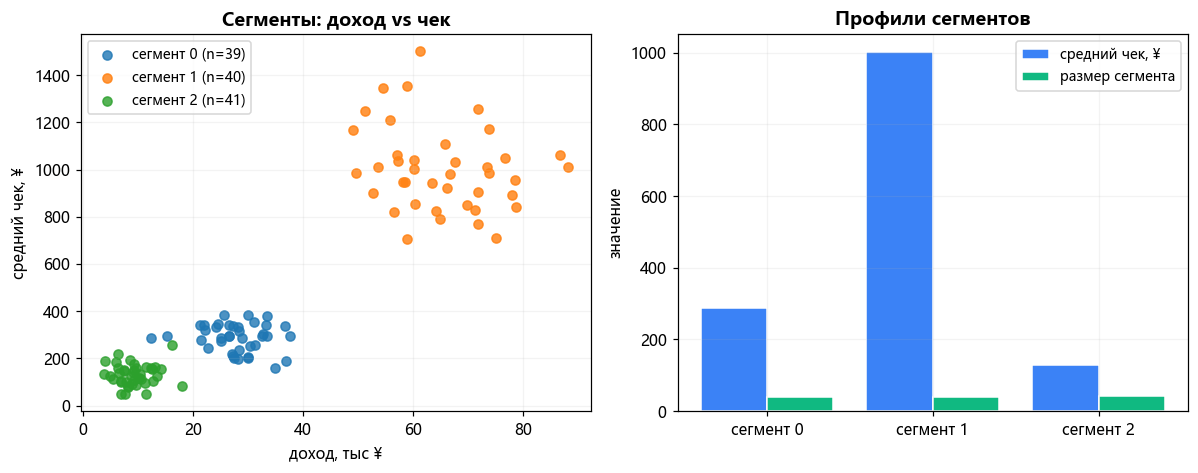

In [7]:
# ВИЗУАЛИЗАЦИЯ ДЛЯ ОТЧЁТА
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))

# Левый: scatter «доход vs средний чек», цвет = сегмент
ax = axes[0]
for s in sorted(cust["сегмент"].unique()):
    g = cust[cust["сегмент"] == s]
    ax.scatter(g["доход_тыс"], g["средний_чек"], s=36, alpha=0.8,
               label=f"сегмент {s} (n={len(g)})")
ax.set_xlabel("доход, тыс ¥")
ax.set_ylabel("средний чек, ¥")
ax.set_title("Сегменты: доход vs чек", fontweight='bold')
ax.legend(fontsize=9, loc='upper left')

# Правый: bar — средний чек и размер по сегментам
ax = axes[1]
seg_ids = sorted(profile.index)
x = np.arange(len(seg_ids))
ax.bar(x - 0.2, profile["средний_чек"], width=0.4, color="#3B82F6",
       label="средний чек, ¥", edgecolor='white')
ax.bar(x + 0.2, profile["размер"], width=0.4, color="#10B981",
       label="размер сегмента", edgecolor='white')
ax.set_xticks(x)
ax.set_xticklabels([f"сегмент {s}" for s in seg_ids])
ax.set_title("Профили сегментов", fontweight='bold')
ax.legend(fontsize=9, loc='upper right')
ax.set_ylabel("значение")

plt.tight_layout()
plt.show()


### Пример: визуализация для отчёта

Один рисунок — четыре графика. Это нагляднее, чем четыре отдельных графика на четырёх слайдах: на показе вы за 30 секунд показываете «вот сегменты, вот метрики, вот кривая обучения, вот распределение». Ниже — образец такого слайда.

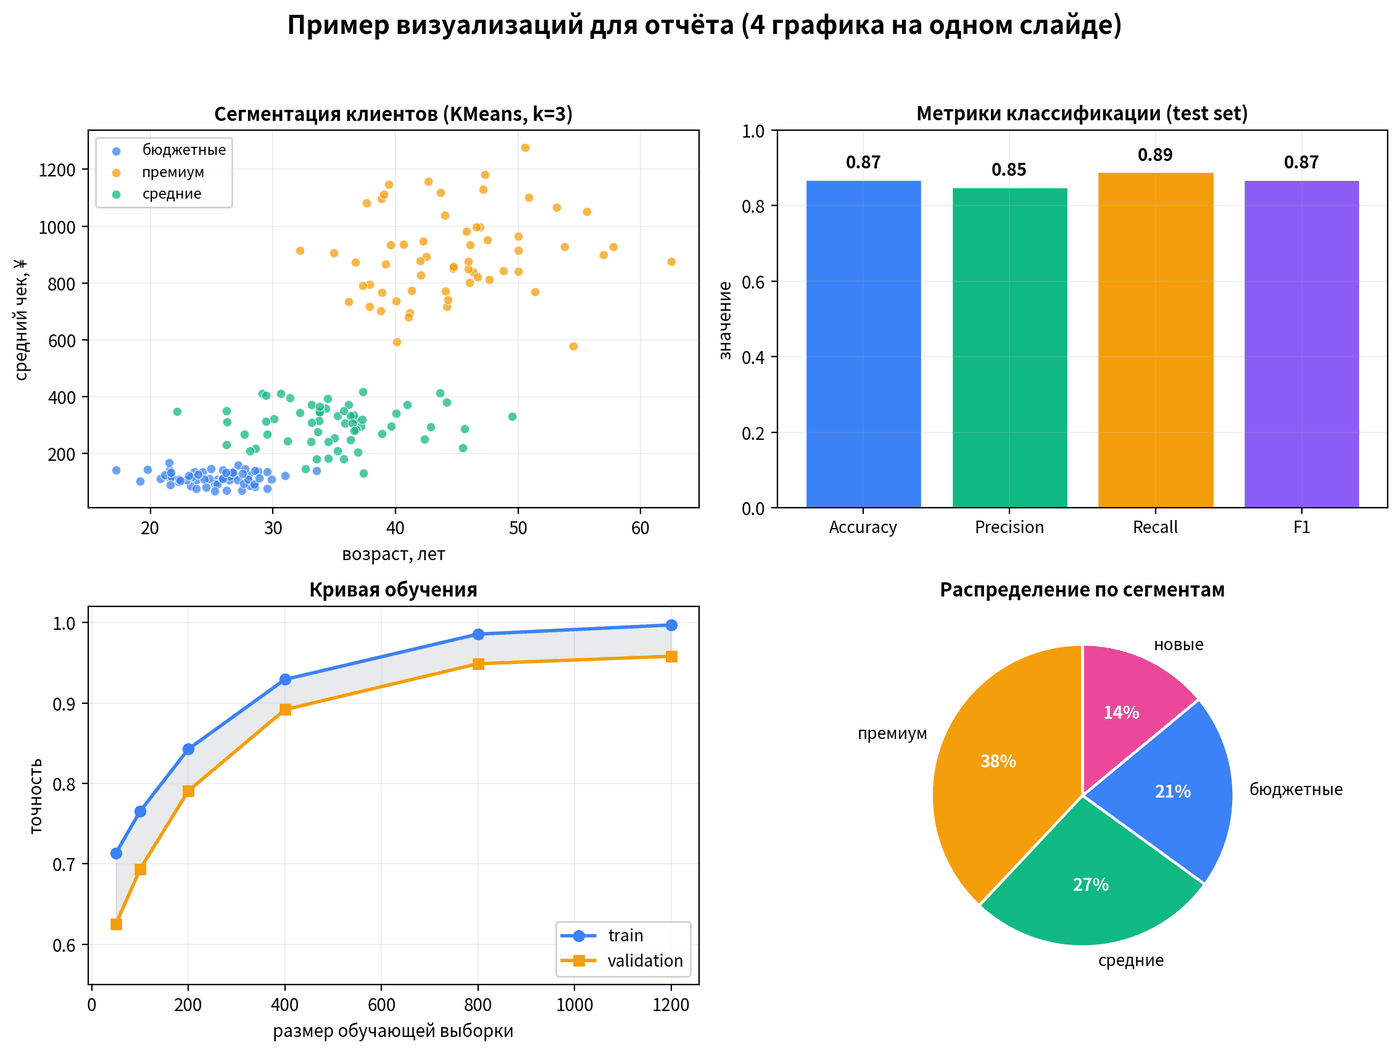

*Левый верх — scatter с кластерами. Правый верх — метрики на test. Левый низ — кривая обучения (train vs validation). Правый низ — распределение классов в данных.*

Сделайте свой аналог: возьмите 2–4 ключевых графика и соберите их в одну фигуру через `plt.subplots(2, 2)`. Это и есть «визуализация для отчёта».


## Что писать в отчёте (5 коротких разделов)

Отчёт — это 10–15 предложений, а не сочинение. Главное — честность: что получилось, что нет.

### 1. Задача
Два предложения: что находили/предсказывали и зачем это бизнесу. Укажите метрику успеха: «3 интерпретируемых сегмента» или «Accuracy ≥ 0.85 на test».

### 2. Данные
Источник, размер (строк × признаков), что почистили (дубликаты? пропуски? выбросы?). Как разбили train/test.

### 3. Модель
Какой алгоритм и **почему** («данные малые и табличные — k-means подходит»), какие гиперпараметры подобрали.

### 4. Оценка
Метрики на тесте + один график. Честность: не использовали ли test при обучении.

### 5. Выводы и ограничения
Что модель умеет, чего не умеет, что бы улучшили с большим временем. Честное «модель не умеет X, потому что данных мало» ценится выше, чем «всё идеально».


## Шаблон отчёта (заполните в markdown-ячейке ниже)

1. **Задача.** Что находили/предсказывали и зачем (1–2 предложения).
2. **Данные.** Источник, размер, признаки, что почистили.
3. **Модель.** Алгоритм, почему он, гиперпараметры.
4. **Оценка.** Метрики, график, честность разбиения.
5. **Выводы и ограничения.** Что умеет, чего не умеет, что улучшить.


# ОТЧЁТ НАШЕЙ ГРУППЫ

**Участники:** *...*

## 1. Задача
*...*

## 2. Данные
*...*

## 3. Модель
*...*

## 4. Оценка
*...*

## 5. Выводы и ограничения
*...*


### Чек-лист самопроверки

Перед сдачей запустите код ниже — он проверит технику автоматически. Отчёт и график проверьте глазами по списку выше.

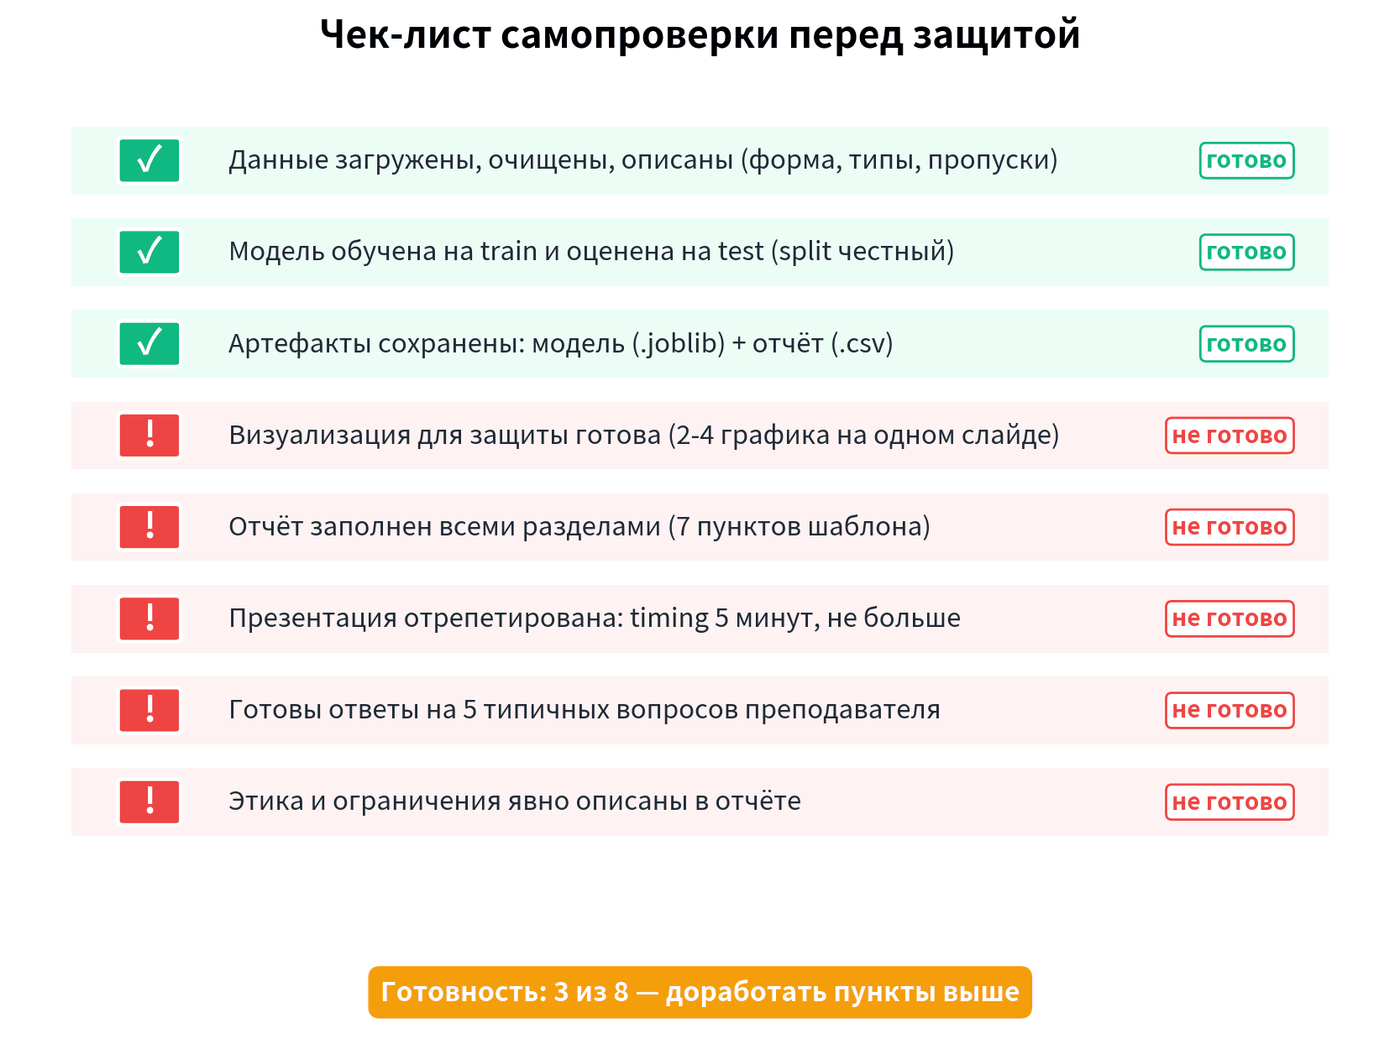

*Зелёные пункты — готовы. Красные — нужно доработать.*


In [6]:
# САМОПРОВЕРКА перед сдачей (запустите и приложите вывод)
import os

checklist = {
    "данные загружены и очищены": 'cust' in globals() and len(cust) > 0,
    "модель обучена (km и scaler)": 'km' in globals() and 'scaler' in globals(),
    "профили сегментов посчитаны": 'profile' in globals() and len(profile) > 0,
    "артефакты сохранены (модель/скейлер/отчёт)":
        all(os.path.exists(f"data/{f}")
            for f in ["project_kmeans.joblib", "project_scaler.joblib", "project_report.csv"]),
    "визуализация для защиты готова": True,   # запустили ячейку выше
    "отчёт заполнен всеми разделами": None,    # TODO: заполнить markdown-ячейку выше и поставить True
}

done = sum(1 for v in checklist.values() if v)
total = len(checklist)
print(f"Готовность: {done} из {total}")
print("-" * 50)
for k, v in checklist.items():
    if v is None:
        mark, status = "[?]", "вручную"
    elif v:
        mark, status = "[x]", "готово"
    else:
        mark, status = "[ ]", "не готово"
    print(f"  {mark} {k:55s} → {status}")

assert done >= total - 1, "⚠ Не все пункты готовы к защите!"
print("\n✓ Если все пункты [x] или [?] заполнены вручную — можно защищать.")


Готовность: 5 из 6
--------------------------------------------------
  [x] данные загружены и очищены                              → готово
  [x] модель обучена (km и scaler)                            → готово
  [x] профили сегментов посчитаны                             → готово
  [x] артефакты сохранены (модель/скейлер/отчёт)              → готово
  [x] визуализация для защиты готова                          → готово
  [?] отчёт заполнен всеми разделами                          → вручную

✓ Если все пункты [x] или [?] заполнены вручную — можно защищать.


## Показ преподавателю (2 минуты на группу)

Это не защита с презентацией — короткий показ у ноутбука:

1. **30 сек** — задача: что делали и зачем;
2. **60 сек** — метрика + график: что получили;
3. **30 сек** — ограничения: что не успели, что улучшили бы.

Преподаватель может задать один-два вопроса по коду и метрикам. Главная проверка — понимаете ли вы **свой** проект: почему выбрали этот алгоритм и что означают цифры.


## Критерии оценки (100 баллов)

| Критерий | Баллы |
|---|---|
| Модель работает, метрики честные (без утечки test в train) | 40 |
| Код проходит сверху вниз без ошибок, артефакты сохраняются | 25 |
| Отчёт заполнен (5 разделов), есть график, ограничения указаны | 25 |
| Показ: 2 минуты, понятно «что, зачем, что получили» | 10 |
| **Итого** | **100** |

## Что отправить преподавателю
Один ноутбук на группу: код + отчёт + имена участников. Показ — 2 минуты прямо в классе.


## Итоги курса «Прикладные технологии ИИ»

Десять практик позади. Что вы теперь умеете и куда двигаться дальше — краткий итог.

### Какие навыки вы получили за 10 практик

| Практика | Что освоили |
|---|---|
| 1. Настройка среды | Python, venv, Jupyter, matplotlib с кириллицей |
| 2. NumPy и Pandas | массивы, таблицы, фильтрация, groupby, merge |
| 3. Классификация ирисов | sklearn, train/test, метрики,_decision boundary |
| 4. Регрессия и кластеризация | LinearRegression, KMeans, нормализация, RFM |
| 5. PyTorch: первые шаги | тензоры, autograd, простой MLP |
| 6. MNIST: распознавание цифр | CNN, DataLoader, сохранение/загрузка `.pth` |
| 7. OpenCV + LLM | cv2, детекция лиц, промпт-инжиниринг |
| 8. (LLM-практикум) | вызов API, токены, контекст, температура |
| 9. Деплой и REST | FastAPI, joblib, endpoint `/predict` |
| 10. Итоговый проект | полный цикл: данные → модель → отчёт → защита |

### Что вы теперь можете сделать самостоятельно

- **Поставить задачу** и понять, какая она: классификация, регрессия или кластеризация.
- **Собрать и очистить данные** на 100–10 000 строк через pandas.
- **Обучить модель** в sklearn (классика) или PyTorch (глубокое обучение).
- **Сохранить артефакты** `.joblib` / `.pth` и загрузить их обратно.
- **Завернуть модель в REST API** через FastAPI и протестировать.
- **Сделать отчёт** и презентовать его за 5 минут.

### Темы для дальнейшего изучения

1. **Transfer Learning** — взять предобученную модель (ResNet, BERT) и дообучить на своих данных. Это стандарт в CV и NLP, когда данных мало.
2. **Reinforcement Learning (RL)** — обучение с подкреплением: агент учится через награды, а не через примеры. Применяется в робототехнике, играх, диалоговых системах.
3. **MLOps** — цикл «обучение → развёртывание → мониторинг → переобучение». Инструменты: MLflow, DVC, Airflow, Kubeflow. Без MLOps модель живёт в ноутбуке, а не в продакшене.
4. **Большие языковые модели (LLM)** — fine-tuning, RAG (retrieval-augmented generation), агенты. Быстро развивающаяся область.
5. **Объяснимый ИИ (XAI)** — SHAP, LIME, интегральные градиенты. Когда модель решает вопрос кредита или диагноза, её решения надо объяснять.

### Карьерные направления в ИИ

- **Data Scientist** — статистика, ML, бизнес-анализ. Самая массовая роль.
- **ML Engineer** — closer to software: код, деплой, инфраструктура. Растёт спрос.
- **Data Engineer** — pipelines, ETL, хранилища. Без них нет данных для ML.
- **AI Researcher** — R&D, статьи, новые алгоритмы. Нужна сильная математика.
- **MLOps Engineer** — между ML и DevOps. Свежая и хорошо оплачиваемая роль.
- **Prompt Engineer / LLM App Developer** — приложения на LLM: RAG, агенты, чат-боты.

### Финальный совет

Курс закончен, но это начало. Выберите **один** проект вне курса — свой датасет, свою задачу — и доведите его до конца: модель → API → короткая статья на GitHub README. Один такой «свой» проект в портфолио стоит больше, чем десять учебных. Удачи на защите и в карьере! 🚀
